# Gradients that respect the cone

Notebook 05 drew which gates a question needs. Gradients inherit that picture: a
parameter that sits outside the cone of an observable cannot change its value, so its
derivative is exactly zero and needs no simulation. Version 0.2.0 builds on this in
three places, all shown here on one small circuit:

1. **weighted Pauli sums**: a Hamiltonian is one request, and its terms share
   simulations when their cones coincide;
2. **PennyLane**: `qml.device("lazyqc.qubit")` with cone-restricted device derivatives;
3. **native gradients**: `adjoint_gradient` and `profile_sensitivity`, which can pick
   parameter shifts or backpropagation for each cone.

In [1]:
import os

# One native thread per library, so timings compare algorithms rather than core counts.
# This has to happen before Qulacs is imported.
for key in ("QULACS_NUM_THREADS", "OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[key] = "1"

import matplotlib.pyplot as plt
import pennylane as qml
from pennylane import numpy as pnp

from lazyqc import Parameter, Program, adjoint_gradient, plan_all, profile_sensitivity
from nbtools import cone_indices, draw_circuit, label, table

## The circuit and its Hamiltonian

Two entangled pairs, (0, 1) and (2, 3), joined by one CX at the end. Five parameters:
`a` to `d` rotate one qubit each, and `e` is reused by two gates. The Hamiltonian has
four terms with different reach: $Z_0$ and $Z_3$ sit at the edges, while $Z_1$ and
$X_1X_2$ sit next to the joining CX.

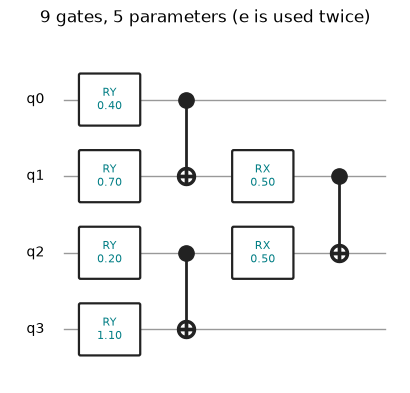

H = +0.5 Z0 -0.3 Z3 +0.8 Z1 +0.4 X1 X2
<H> = 1.0794331283215908


In [2]:
names = ["a", "b", "c", "d", "e"]
p = {n: Parameter(n) for n in names}
values = dict(zip(names, [0.4, 0.7, 0.2, 1.1, 0.5]))

program = Program(4)
for q, n in enumerate("abcd"):
    program = program.ry(q, p[n])
program = program.cx(0, 1).cx(2, 3).rx(1, p["e"]).rx(2, p["e"]).cx(1, 2).bind(**values)

hamiltonian = [(0.5, {0: "Z"}), (-0.3, {3: "Z"}), (0.8, {1: "Z"}), (0.4, {1: "X", 2: "X"})]
operations = program.resolved_operations()

draw_circuit(program, title=f"{len(operations)} gates, 5 parameters (e is used twice)")
plt.show()
print("H =", " ".join(f"{c:+.1f} {label(t)}" for c, t in hamiltonian))
print("<H> =", plan_all([program.expectation(hamiltonian)]).collect().values[0])

## One Hamiltonian, one request

`program.expectation` accepts the list of `(coefficient, term)` pairs and returns a
single request, so the sum is planned as a whole. Below, each term gets its own cone.
Terms with the same cone are served by the same simulation: that is what makes a
many-term Hamiltonian cheaper than one run per term.

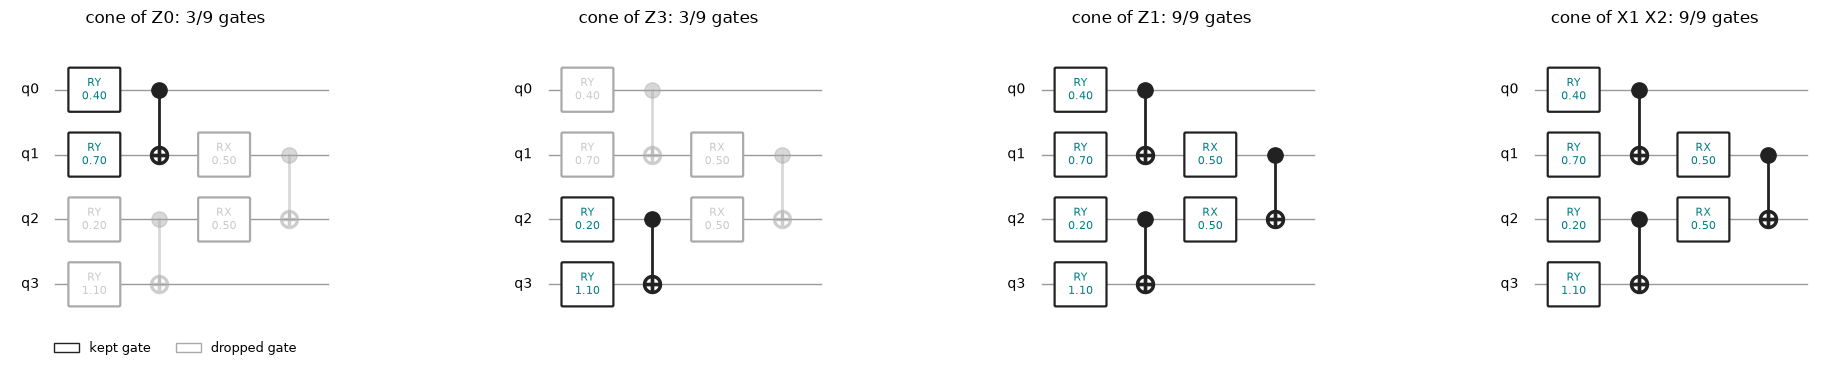

| term | coefficient | gates kept |
|---|---|---|
| Z0 | 0.500 | 3 |
| Z3 | -0.300 | 3 |
| Z1 | 0.800 | 9 |
| X1 X2 | 0.400 | 9 |

4 terms, 3 distinct cones: [['Z0'], ['Z3'], ['Z1', 'X1 X2']]


In [3]:
fig, axes = plt.subplots(1, len(hamiltonian), figsize=(5 * len(hamiltonian), 3.8))
rows, cones = [], {}
for k, (ax, (coeff, term)) in enumerate(zip(axes, hamiltonian)):
    keep = cone_indices(operations, program.expectation(term).observable)
    cones.setdefault(frozenset(keep), []).append(label(term))
    draw_circuit(program, ax=ax, keep=keep, legend=k == 0,
                 title=f"cone of {label(term)}: {len(keep)}/{len(operations)} gates")
    rows.append((label(term), coeff, len(keep)))
fig.tight_layout()
plt.show()
table(rows, ["term", "coefficient", "gates kept"])
print(f"{len(hamiltonian)} terms, {len(cones)} distinct cones:", list(cones.values()))

## Through PennyLane

The same circuit as a QNode on `lazyqc.qubit`. With `diff_method="best"` the device
builds shifted circuits only for the parameters inside the cone of each term. Every
other entry of the gradient is a *structural zero*: it is reported as exactly `0.0` and
counted in `dev.last_stats`, instead of being simulated and coming back as rounding noise.

In [4]:
H = qml.Hamiltonian([c for c, _ in hamiltonian],
                    [qml.Z(0), qml.Z(3), qml.Z(1), qml.X(1) @ qml.X(2)])

def ansatz(w):
    for q in range(4):
        qml.RY(w[q], wires=q)
    qml.CNOT(wires=[0, 1])
    qml.CNOT(wires=[2, 3])
    qml.RX(w[4], wires=1)
    qml.RX(w[4], wires=2)
    qml.CNOT(wires=[1, 2])
    return qml.expval(H)

w = pnp.array([values[n] for n in names], requires_grad=True)

dev = qml.device("lazyqc.qubit", wires=4)
lazy = qml.QNode(ansatz, dev, diff_method="best")
reference = qml.QNode(ansatz, qml.device("default.qubit", wires=4), diff_method="backprop")

g_lazy, g_ref = qml.grad(lazy)(w), qml.grad(reference)(w)
table([(n, float(a), float(b), abs(float(a) - float(b))) for n, a, b in zip(names, g_lazy, g_ref)],
      ["parameter", "lazyqc.qubit", "default.qubit", "difference"], digits=12)
print("device statistics:", dev.last_stats)

| parameter | lazyqc.qubit | default.qubit | difference |
|---|---|---|---|
| a | -0.403815034421 | -0.403815034421 | 5.6e-17 |
| b | -0.110643692394 | -0.110643692394 | 1.1e-16 |
| c | 0.0270346913685 | 0.0270346913685 | 8.7e-17 |
| d | 0.262032764257 | 0.262032764257 | 3.9e-16 |
| e | -0.270191310268 | -0.270191310268 | 1.7e-16 |

device statistics: {'tapes': 1, 'requests': 32, 'shift_terms': 24, 'skipped_structural_zeros': 8}


The values agree with dense backpropagation. The statistics count the shift terms
(one per parameter occurrence and Hamiltonian term) and how many of them the cones made
unnecessary. Every parameter reaches some term here, so no gradient entry is zero, but
the pairs that never meet are skipped. The next circuit isolates a parameter on purpose.

In [5]:
dev2 = qml.device("lazyqc.qubit", wires=3)

@qml.qnode(dev2, diff_method="best")
def isolated_circuit(w):
    qml.RY(w[0], wires=0)
    qml.CNOT(wires=[0, 1])
    qml.RY(w[1], wires=2)
    return qml.expval(qml.Z(0)), qml.expval(qml.Z(1))

stacked = lambda w: pnp.stack(isolated_circuit(w))
jac = qml.jacobian(stacked)(pnp.array([0.4, 0.7], requires_grad=True))
print("Jacobian (rows: <Z0>, <Z1>; columns: t, u):")
print(pnp.array(jac))
print("device statistics:", dev2.last_stats)

Jacobian (rows: <Z0>, <Z1>; columns: t, u):
[[-0.38941834  0.        ]
 [-0.38941834  0.        ]]
device statistics: {'tapes': 1, 'requests': 4, 'shift_terms': 4, 'skipped_structural_zeros': 2}


Parameter `u` acts on qubit 2, which no cone of $Z_0$ or $Z_1$ reaches, so its column
is exactly zero and none of its shifted circuits were run (`skipped_structural_zeros`).

## The native gradient

Outside PennyLane, `adjoint_gradient(program, observables, weights)` returns the
gradient of the weighted loss $\sum_k w_k \langle O_k \rangle$ for every bound symbolic
parameter. Inside each cone it runs one Qulacs backpropagation, shared by all
observables with that cone, and it sums every occurrence of a reused parameter (`e`
here). Using the Hamiltonian terms as observables reproduces the QNode gradient.

In [6]:
observables = [term for _, term in hamiltonian]
weights = [c for c, _ in hamiltonian]
native = adjoint_gradient(program, observables, weights)

table([(n, native[n], float(g_ref[i]), abs(native[n] - float(g_ref[i]))) for i, n in enumerate(names)],
      ["parameter", "adjoint_gradient", "default.qubit", "difference"], digits=12)

| parameter | adjoint_gradient | default.qubit | difference |
|---|---|---|---|
| a | -0.403815034421 | -0.403815034421 | 1.1e-16 |
| b | -0.110643692394 | -0.110643692394 | 0 |
| c | 0.0270346913685 | 0.0270346913685 | 1.1e-16 |
| d | 0.262032764257 | 0.262032764257 | 3.9e-16 |
| e | -0.270191310268 | -0.270191310268 | 0 |

## Shift or adjoint, cone by cone

`profile_sensitivity` reports the derivative of each observable with respect to chosen
gate occurrences (indices into the resolved gate list), plus a bound on how much the
outputs can move for given angle changes. `method="auto"` compares the estimated cost
of two shifts per rotation with three adjoint sweeps *in each cone* and records the
choice per observable.

In [7]:
rotations = [i for i, g in enumerate(operations) if g.angle is not None]
profile = profile_sensitivity(program, observables, rotations, evaluation_error=1e-9, method="auto")

rows = [(label(t), method, sum(rel), len(rotations)) for t, method, rel in
        zip(observables, profile.methods, profile.relevant)]
table(rows, ["observable", "method", "rotations in cone", "rotations profiled"])

grad_e = profile.parameter_gradient("e")
print("d<O_k>/de, summed over both uses of e:", [round(g, 6) for g in grad_e])

| observable | method | rotations in cone | rotations profiled |
|---|---|---|---|
| Z0 | adjoint | 2 | 6 |
| Z3 | adjoint | 2 | 6 |
| Z1 | adjoint | 6 | 6 |
| X1 X2 | adjoint | 6 | 6 |

d<O_k>/de, summed over both uses of e: [0.0, 0.0, -0.337739, -0.0]


## What the pictures teach

- A gradient inherits the cone: a parameter outside the cone of every term has an
  exactly zero derivative and costs nothing, while dense simulation returns noise.
- A Hamiltonian is one request. Terms with equal cones share a simulation, in the
  forward pass and in the adjoint backpropagation alike.
- `lazyqc.qubit` and `adjoint_gradient` agree with dense backpropagation to rounding,
  so cone restriction changes the cost, not the answer.
- `method="auto"` decides per cone and records the choice in `profile.methods`. Here
  adjoint wins everywhere, since each cone holds several rotations.

## Try it yourself

- Move the joining `cx(1, 2)` to the front of the circuit and watch the cones of $Z_0$
  and $Z_3$ grow.
- Add a fifth term `{0: "X", 3: "X"}` and count the distinct cones again.
- Use `qml.device("lazyqc.qubit", wires=4)` with `diff_method="parameter-shift"` and
  compare `dev.last_stats["requests"]` with the `"best"` run.